In [1]:
import geopandas as gpd
import pandas as pd 
import numpy as np 

from shapely import box

from tqdm import tqdm 
import os

In [2]:
# read_file no acepta crs= (se ignora: ver warning). Se usa el CRS del .prj y se reproyecta a WGS84
blocks_peru = gpd.read_file("../data/raw_data/Manzana_2017/MANZANA.shp").to_crs("EPSG:4326")

blocks_peru.columns
blocks_peru.shape
blocks_peru.IDMANZANA.is_unique
### Load a dataset at district level and dummy for urban area 
districts_infoarea = pd.read_stata("../data/raw_data/Census2017_district.dta")

districts_urban = districts_infoarea[districts_infoarea['area'] == 1].copy()
districts_urban.shape
blocks_peru_urban = blocks_peru.merge(districts_urban, 
                                      left_on='UBIGEO',
                                      right_on='ubigeo',
                                      how='inner')

blocks_peru_urban = gpd.GeoDataFrame(blocks_peru_urban, 
                                     geometry='geometry', 
                                     crs="EPSG:4326")

# Geometrías inválidas generan errores en Earth Engine
blocks_peru_urban["geometry"] = blocks_peru_urban.geometry.make_valid()
blocks_peru_urban = blocks_peru_urban[~blocks_peru_urban.geometry.is_empty].copy()

In [3]:
# ------------------------------------------------------------------
# 1. Unir todas las geometrías de blocks_peru_urban en un solo GeoDataFrame
# ------------------------------------------------------------------
blocks_union = gpd.GeoDataFrame(
    geometry=[blocks_peru_urban.geometry.union_all()],   
    crs=blocks_peru_urban.crs
)

# ------------------------------------------------------------------
# 2. Proyectar a EPSG:32718 (UTM 18S, en metros)
# ------------------------------------------------------------------
blocks_proj = blocks_peru_urban.to_crs("EPSG:32718")
blocks_union_proj = blocks_union.to_crs("EPSG:32718")

In [4]:
# ------------------------------------------------------------------
# 3. Crear una grilla de 2 km x 2 km sobre la extensión de las manzanas
# ------------------------------------------------------------------
CELL_SIZE = 2000  # metros (lado de la celda)

xmin, ymin, xmax, ymax = blocks_proj.total_bounds

# Alinear el origen a múltiplos de CELL_SIZE (grilla estable entre corridas)
xmin = np.floor(xmin / CELL_SIZE) * CELL_SIZE
ymin = np.floor(ymin / CELL_SIZE) * CELL_SIZE

xs = np.arange(xmin, xmax, CELL_SIZE)
ys = np.arange(ymin, ymax, CELL_SIZE)
xx, yy = np.meshgrid(xs, ys)
xx, yy = xx.ravel(), yy.ravel()

grid = gpd.GeoDataFrame(
    geometry=box(xx, yy, xx + CELL_SIZE, yy + CELL_SIZE),
    crs="EPSG:32718"
)

In [5]:
# Conservar solo las celdas que intersectan alguna manzana urbana

idx = gpd.sjoin(grid, blocks_proj[["geometry"]],
                 predicate="intersects").index.unique()

grid = grid.loc[idx].reset_index(drop=True)

# grid = grid[grid.intersects(blocks_union_proj.geometry.iloc[0])].reset_index(drop=True)

# ------------------------------------------------------------------
# 4. ID de cada grid y área en km²
# ------------------------------------------------------------------

grid["ID"] = [f"G{i:07d}" for i in range(1, len(grid) + 1)]
grid["area_km2"] = grid.geometry.area / 1e6

grid = grid[["ID", "area_km2", "geometry"]]

print(grid.shape)
print(grid["area_km2"].describe())   # todas deberían ser 4.0 km²

# Volver a WGS84 si luego lo usarás en Earth Engine
grid_wgs84 = grid.to_crs("EPSG:4326")

(6176, 3)
count    6176.0
mean        4.0
std         0.0
min         4.0
25%         4.0
50%         4.0
75%         4.0
max         4.0
Name: area_km2, dtype: float64


In [6]:
grid_wgs84.to_file(r"..\data\temporal_data\shapefile\DatasetGrids2km.shp")

In [7]:
grid_wgs84.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 6176 entries, 0 to 6175
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   ID        6176 non-null   str     
 1   area_km2  6176 non-null   float64 
 2   geometry  6176 non-null   geometry
dtypes: float64(1), geometry(1), str(1)
memory usage: 193.1 KB


<Axes: >

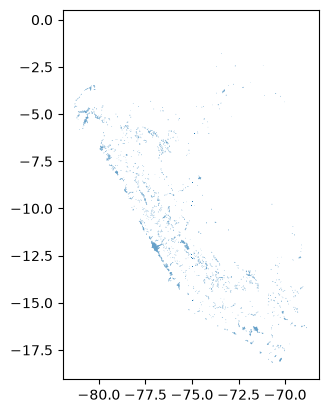

In [8]:
grid_wgs84.plot()

<Axes: >

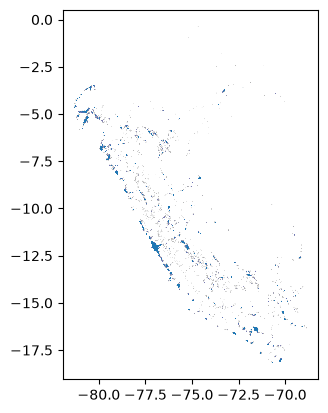

In [9]:
blocks_peru_urban.plot()